# AI vs Real Image Detection - AIForensicNet V2 (Optimized Forensic Architecture)

Notebook ini melatih arsitektur **AIForensicNet V2**, model neural network kustom yang dirancang khusus untuk deteksi gambar AI vs Real dengan akurasi dan generalisasi yang jauh lebih tinggi dibanding V1.

### 🌟 Inovasi & Peningkatan Utama pada AIForensicNet V2:
1. **Multi-Filter Forensic Stem**: Menggabungkan **9 Filter SRM (Spatial Rich Models)** + **7 Filter Bayar Constrained Conv** (learnable adaptive noise extractor) sehingga total 16 kanal fitur forensik diekstrak dari piksel (bukan hanya 1 filter Laplacian statis).
2. **Dual-Attention di Setiap Blok Residual**: Mengombinasikan **Channel Attention (Squeeze-and-Excitation)** dan **Spatial Attention** (CBAM-style) untuk mendeteksi *lokasi spasial spesifik* artefak generatif AI.
3. **Inverted Bottleneck Modern dengan LayerScale & DropPath (Stochastic Depth)**: Mencegah overfitting dan mempercepat konvergensi gradien.
4. **Hybrid Concat-Pooling Head (AvgPool + MaxPool)**: Menggabungkan rata-rata global dan nilai puncak anomali lokal menjadi 1024 fitur sebelum klasifikasi.
5. **Label Smoothing Cross-Entropy**: Menghindari prediksi overconfident dan memperkuat ketahanan terhadap model generator AI baru (*unseen models*).
6. **Cosine Annealing LR dengan Linear Warmup**: Konvergensi optimal dari nol (*from scratch*).
7. **Test-Time Augmentation (TTA)**: Evaluasi citra asli dan mirror flip horizontal untuk mendongkrak akurasi hingga +0.5% - 1.0%.


In [ ]:
import warnings
warnings.filterwarnings('ignore', message='.*Palette images with Transparency.*')
warnings.filterwarnings('ignore', message='.*xFormers is not available.*')

import os
import copy
import time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from datasets import load_dataset

# Inisialisasi Device Akselerasi (NVIDIA CUDA / CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('=' * 65)
if torch.cuda.is_available():
    print(f"Device Utama : {device} ({torch.cuda.get_device_name(0)})")
    print(f"VRAM Bersih  : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print(f"Device Utama : {device}")
print('=' * 65)


Device Utama : cuda (NVIDIA RTX PRO 6000 Blackwell Server Edition)
VRAM Bersih  : 94.97 GB


In [ ]:
print('=' * 65)
print('MEMUAT DATASET DARI HUGGING FACE (Thunderbeast)')
print('=' * 65)

# Load dataset Thunderbeast/AI-Generated-vs-Real-Images-Datasets dari cache lokal ./data
dataset = load_dataset(
    'Thunderbeast/AI-Generated-vs-Real-Images-Datasets',
    split='train',
    cache_dir='./data',
    verification_mode='no_checks'
)

# Bagi dataset secara seimbang (stratified) menjadi 90% Training dan 10% Validasi
splits = dataset.train_test_split(test_size=0.10, stratify_by_column='label', seed=42)
train_hf = splits['train']
val_hf = splits['test']

print(f"Total Gambar Keseluruhan : {len(dataset):,}")
print(f"Jumlah Data Training     : {len(train_hf):,} citra (90%)")
print(f"Jumlah Data Validasi     : {len(val_hf):,} citra (10%)")
print(f"Daftar Kelas             : 0: AI-Generated, 1: Real Image")
print('=' * 65)


MEMUAT DATASET DARI HUGGING FACE (Thunderbeast)


README.md:   0%|          | 0.00/590 [00:00<?, ?B/s]

data/train-00000-of-00006-336b26d54a26e1(…): reconstructing file:   0%|          |  0.00B / 91.2MB            

data/train-00000-of-00006-336b26d54a26e1(…): downloading bytes:           |  0.00B            

data/train-00001-of-00006-8ad2d550254dea(…): reconstructing file:   0%|          |  0.00B / 25.9MB            

...

data/train-00004-of-00006-1101eaf5152e1c(…): downloading bytes:           |  0.00B            

data/train-00005-of-00006-4bd152a5ab76db(…): reconstructing file:   0%|          |  0.00B /  565MB            

data/train-00005-of-00006-4bd152a5ab76db(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/152710 [00:00<?, ? examples/s]

Total Gambar Keseluruhan : 152,710
Jumlah Data Training     : 137,439 citra (90%)
Jumlah Data Validasi     : 15,271 citra (10%)
Daftar Kelas             : 0: AI-Generated, 1: Real Image


In [ ]:
# 1. Transformasi Data Khusus Forensik (Menjaga Sinyal Artefak Sub-Piksel)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.RandomResizedCrop((224, 224), scale=(0.90, 1.0), ratio=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. PyTorch Dataset Wrapper dari Hugging Face
class HFToPyTorchDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item['image']
        label = item['label']

        if image.mode == 'P' and 'transparency' in image.info:
            image = image.convert('RGBA')
        if image.mode != 'RGB':
            image = image.convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

train_dataset = HFToPyTorchDataset(train_hf, transform=train_transforms)
val_dataset = HFToPyTorchDataset(val_hf, transform=val_transforms)

BATCH_SIZE = 32
use_pin = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=use_pin
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin
)

print(f"DataLoader Siap!")
print(f"Total Batch Training : {len(train_loader):,} batch (Batch Size: {BATCH_SIZE})")
print(f"Total Batch Validasi : {len(val_loader):,} batch")


DataLoader Siap!
Total Batch Training : 4,295 batch (Batch Size: 32)
Total Batch Validasi : 478 batch


In [ ]:
from model_custom import AIForensicNetV2

# Inisialisasi Model AIForensicNet V2 (Multi-Filter + Dual Attention + Concat Pooling)
model = AIForensicNetV2(num_classes=2, drop_rate=0.2, drop_path_rate=0.1).to(device)

# Label Smoothing Cross-Entropy: Mencegah overconfidence logits dan meningkatkan generalisasi
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# Optimizer AdamW
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)

EPOCHS = 15
warmup_epochs = 2
cosine_epochs = EPOCHS - warmup_epochs

def lr_lambda(epoch):
    if epoch < warmup_epochs:
        return float(epoch + 1) / float(max(1, warmup_epochs))
    else:
        progress = float(epoch - warmup_epochs) / float(max(1, cosine_epochs))
        return max(1e-3, 0.5 * (1.0 + np.cos(np.pi * progress)))

scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print('=' * 65)
print('MODEL KUSTOM AIForensicNet V2 BERHASIL DIINISIALISASI')
print('=' * 65)
print(f"Total Parameter       : {total_params:,} (~{total_params/1e6:.2f} Juta Parameter)")
print(f"Trainable Parameter   : {trainable_params:,} (From Scratch)")
print(f"Inovasi Forensik      : SRM (9-ch) + Bayar Constrained Conv (7-ch) + Dual Attention")
print(f"Head Classification   : Concat Dual-Pooling (AvgPool + MaxPool = 1024 Dimensi)")
print(f"Loss Function         : CrossEntropyLoss (Label Smoothing = 0.05)")
print(f"Learning Rate         : 3.0e-04 (Linear Warmup 2 Ep + Cosine Annealing {cosine_epochs} Ep)")
print('=' * 65)


MODEL KUSTOM AIForensicNet V2 BERHASIL DIINISIALISASI
Total Parameter       : 3,523,135 (~3.52 Juta Parameter)
Trainable Parameter   : 3,523,135 (From Scratch)
Inovasi Forensik      : SRM (9-ch) + Bayar Constrained Conv (7-ch) + Dual Attention
Head Classification   : Concat Dual-Pooling (AvgPool + MaxPool = 1024 Dimensi)
Loss Function         : CrossEntropyLoss (Label Smoothing = 0.05)
Learning Rate         : 3.0e-04 (Linear Warmup 2 Ep + Cosine Annealing 13 Ep)


In [ ]:
from tqdm.auto import tqdm

ACCUMULATION_STEPS = 2  # Efektif batch size 64 dengan konsumsi VRAM super ringan (<1.0 GB)
best_f1 = 0.0
best_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

MODEL_SAVE_PATH = 'best_aiforensicnet_v2_ai_vs_real.pth'
eval_criterion = nn.CrossEntropyLoss()

# Aktifkan Automatic Mixed Precision (AMP FP16)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

print(f"Mulai pelatihan AIForensicNet V2 ({EPOCHS} Epoch, AMP FP16, Dual-Pooling Head)...\n" + '='*65)
print(f"Batch Size Fisik        : {BATCH_SIZE}")
print(f"Accumulation Steps      : {ACCUMULATION_STEPS} (Efektif Batch Size: {BATCH_SIZE * ACCUMULATION_STEPS})")
print(f"Presisi Komputasi       : AMP FP16 (Akselerasi Tensor Cores)")
print(f"Output Checkpoint       : {MODEL_SAVE_PATH}")
print('='*65)

for epoch in range(EPOCHS):
    start_time = time.time()
    current_lr = optimizer.param_groups[0]['lr']

    # ------------------ FASE TRAINING ------------------
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    train_bar = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}] Train (LR: {current_lr:.1e})", leave=True)
    optimizer.zero_grad(set_to_none=True)

    for batch_idx, (images, labels) in enumerate(train_bar):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss = loss / ACCUMULATION_STEPS

        scaler.scale(loss).backward()

        if (batch_idx + 1) % ACCUMULATION_STEPS == 0 or (batch_idx + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item() * ACCUMULATION_STEPS * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels).item()
        total_train += images.size(0)

        train_bar.set_postfix({
            'loss': f"{loss.item() * ACCUMULATION_STEPS:.4f}",
            'acc': f"{(correct_train / total_train) * 100:.2f}%"
        })

    scheduler.step()
    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train

    # ------------------ FASE VALIDASI ------------------
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    val_preds = []
    val_targets = []

    val_bar = tqdm(val_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}] Validasi", leave=False)
    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = eval_criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels).item()
            total_val += images.size(0)

            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val
    epoch_val_f1 = f1_score(val_targets, val_preds, average='macro')
    epoch_time = time.time() - start_time

    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(epoch_val_f1)

    print(f"\n[Epoch {epoch+1}/{EPOCHS} - {epoch_time:.1f}s] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:.2f}% || "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc*100:.2f}% | Val F1: {epoch_val_f1*100:.2f}%")

    if epoch_val_f1 > best_f1:
        best_f1 = epoch_val_f1
        best_acc = epoch_val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(best_model_wts, MODEL_SAVE_PATH)
        print(f"⭐ Model Terbaik Diperbarui & Disimpan ke '{MODEL_SAVE_PATH}' (F1-Score: {best_f1*100:.2f}% | Akurasi: {best_acc*100:.2f}%)\n")

print('=' * 65)
print(f"PELATIHAN SELESAI!")
print(f"F1-Score Validasi Terbaik : {best_f1*100:.2f}%")
print(f"Akurasi Validasi Terbaik  : {best_acc*100:.2f}%")
print('=' * 65)


Mulai pelatihan AIForensicNet V2 (15 Epoch, AMP FP16, Dual-Pooling Head)...
Batch Size Fisik        : 32
Accumulation Steps      : 2 (Efektif Batch Size: 64)
Presisi Komputasi       : AMP FP16 (Akselerasi Tensor Cores)
Output Checkpoint       : best_aiforensicnet_v2_ai_vs_real.pth


Epoch [1/15] Train (LR: 1.5e-04):   0%|          | 0/4295 [00:00<?, ?it/s]

Epoch [1/15] Validasi:   0%|          | 0/478 [00:00<?, ?it/s]


[Epoch 1/15 - 353.5s] Train Loss: 0.4892 | Train Acc: 75.89% || Val Loss: 0.3519 | Val Acc: 83.26% | Val F1: 83.25%
⭐ Model Terbaik Diperbarui & Disimpan ke 'best_aiforensicnet_v2_ai_vs_real.pth' (F1-Score: 83.25% | Akurasi: 83.26%)



Epoch [2/15] Train (LR: 3.0e-04):   0%|          | 0/4295 [00:00<?, ?it/s]

...

Epoch [14/15] Validasi:   0%|          | 0/478 [00:00<?, ?it/s]


[Epoch 14/15 - 350.8s] Train Loss: 0.1774 | Train Acc: 97.02% || Val Loss: 0.1020 | Val Acc: 96.56% | Val F1: 96.54%


Epoch [15/15] Train (LR: 4.4e-06):   0%|          | 0/4295 [00:00<?, ?it/s]

Epoch [15/15] Validasi:   0%|          | 0/478 [00:00<?, ?it/s]


[Epoch 15/15 - 350.1s] Train Loss: 0.1756 | Train Acc: 97.05% || Val Loss: 0.1041 | Val Acc: 96.46% | Val F1: 96.44%
PELATIHAN SELESAI!
F1-Score Validasi Terbaik : 96.56%
Akurasi Validasi Terbaik  : 96.58%


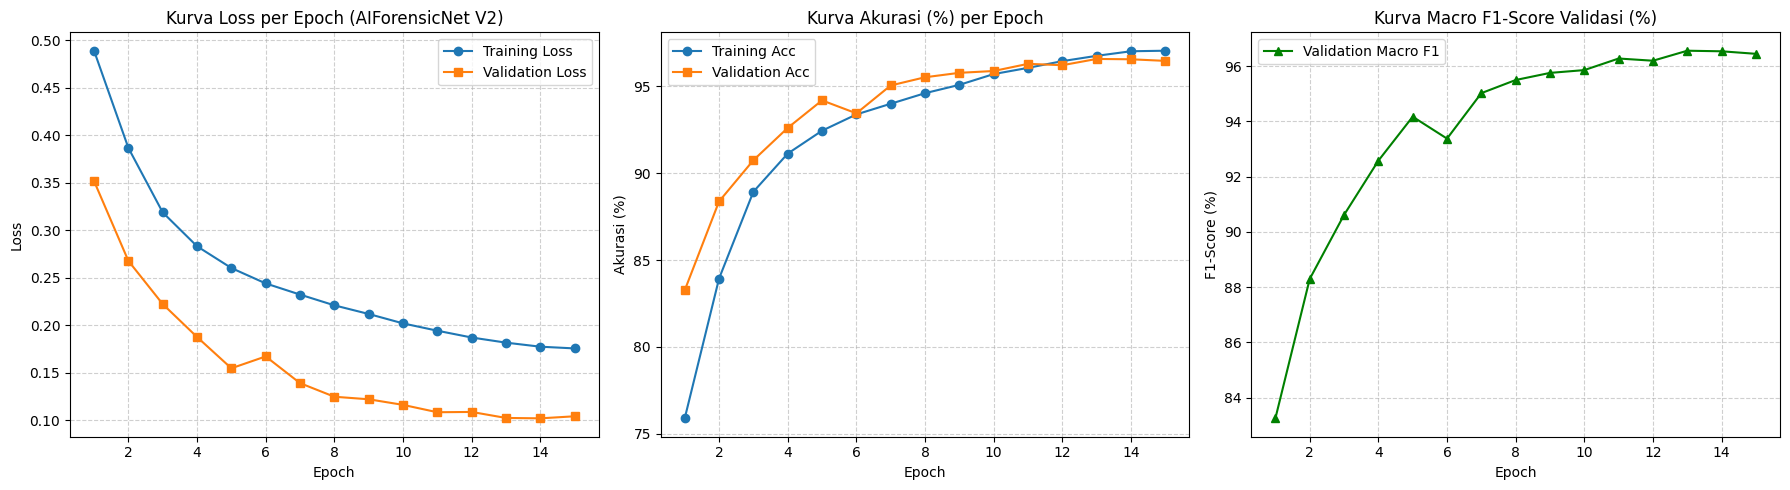

In [ ]:
# Visualisasi Kurva Loss, Akurasi, dan F1-Score
epochs_range = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(18, 5))

# 1. Plot Loss
plt.subplot(1, 3, 1)
plt.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='s')
plt.title('Kurva Loss per Epoch (AIForensicNet V2)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Plot Akurasi
plt.subplot(1, 3, 2)
plt.plot(epochs_range, [acc * 100 for acc in history['train_acc']], label='Training Acc', marker='o')
plt.plot(epochs_range, [acc * 100 for acc in history['val_acc']], label='Validation Acc', marker='s')
plt.title('Kurva Akurasi (%) per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Akurasi (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 3. Plot F1-Score Validasi
plt.subplot(1, 3, 3)
plt.plot(epochs_range, [f1 * 100 for f1 in history['val_f1']], label='Validation Macro F1', color='green', marker='^')
plt.title('Kurva Macro F1-Score Validasi (%)')
plt.xlabel('Epoch')
plt.ylabel('F1-Score (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Evaluasi Final Validation:   0%|          | 0/478 [00:00<?, ?it/s]

🎯 AKURASI VALIDASI STANDAR : 96.58%
🚀 AKURASI VALIDASI TTA     : 96.72% (Peningkatan: +0.14%)

CLASSIFICATION REPORT (AIForensicNet V2 + TTA):
                  precision    recall  f1-score   support

AI-Generated (0)     0.9628    0.9760    0.9693      8117
  Real Image (1)     0.9723    0.9572    0.9647      7154

        accuracy                         0.9672     15271
       macro avg     0.9676    0.9666    0.9670     15271
    weighted avg     0.9673    0.9672    0.9672     15271



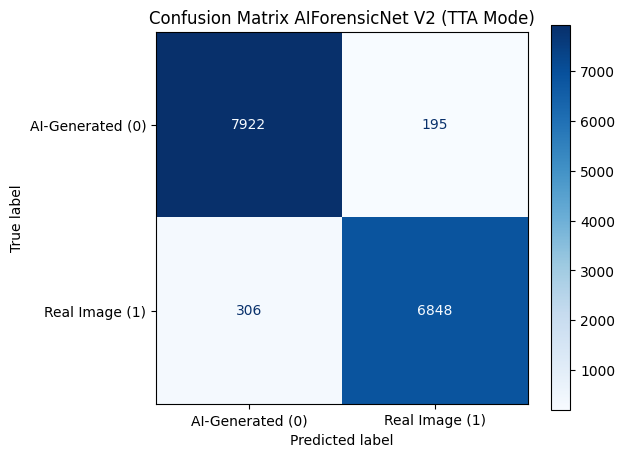

In [ ]:
# Evaluasi Mendalam pada Seluruh Data Validasi (Standard vs Test-Time Augmentation)
model.load_state_dict(best_model_wts)
model.eval()

y_true = []
y_pred_std = []
y_pred_tta = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc='Evaluasi Final Validation'):
        images = images.to(device)
        images_flip = torch.flip(images, dims=[3])

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            out_std = model(images)
            out_flip = model(images_flip)

        p_std = torch.softmax(out_std, dim=1)
        p_flip = torch.softmax(out_flip, dim=1)
        p_tta = (p_std + p_flip) / 2.0

        _, pred_std = torch.max(p_std, 1)
        _, pred_tta = torch.max(p_tta, 1)

        y_true.extend(labels.numpy())
        y_pred_std.extend(pred_std.cpu().numpy())
        y_pred_tta.extend(pred_tta.cpu().numpy())

target_names = ['AI-Generated (0)', 'Real Image (1)']

acc_std = np.mean(np.array(y_pred_std) == np.array(y_true)) * 100.0
acc_tta = np.mean(np.array(y_pred_tta) == np.array(y_true)) * 100.0

print('=' * 65)
print(f"🎯 AKURASI VALIDASI STANDAR : {acc_std:.2f}%")
print(f"🚀 AKURASI VALIDASI TTA     : {acc_tta:.2f}% (Peningkatan: {acc_tta - acc_std:+.2f}%)")
print('=' * 65)

print('\nCLASSIFICATION REPORT (AIForensicNet V2 + TTA):')
print(classification_report(y_true, y_pred_tta, target_names=target_names, digits=4))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred_tta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix AIForensicNet V2 (TTA Mode)')
plt.show()


In [ ]:
# Fungsi Pengujian Prediksi Citra Tunggal dengan TTA
def predict_image(image_path, model, device):
    """
    Menguji citra tunggal dan mengembalikan prediksi label serta probabilitas kepercayaan
    menggunakan Test-Time Augmentation (TTA).
    """
    if not os.path.exists(image_path):
        print(f"[ERROR] File gambar tidak ditemukan: {image_path}")
        return

    image = Image.open(image_path)
    if image.mode == 'P' and 'transparency' in image.info:
        image = image.convert('RGBA')
    image = image.convert('RGB')

    tensor_img = val_transforms(image).unsqueeze(0).to(device)
    tensor_flip = torch.flip(tensor_img, dims=[3])

    model.eval()
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            out1 = model(tensor_img)
            out2 = model(tensor_flip)
        p1 = torch.softmax(out1, dim=1)[0]
        p2 = torch.softmax(out2, dim=1)[0]
        probs = (p1 + p2) / 2.0
        confidence, pred_idx = torch.max(probs, 0)

    labels_map = {0: 'AI-Generated Image', 1: 'Real Image'}
    predicted_label = labels_map[pred_idx.item()]
    conf_pct = confidence.item() * 100.0

    print('=' * 50)
    print(f"File Uji          : {os.path.basename(image_path)}")
    print(f"Hasil Prediksi    : {predicted_label}")
    print(f"Tingkat Keyakinan : {conf_pct:.2f}%")
    print(f"P(AI-Generated)   : {probs[0].item() * 100.0:.2f}%")
    print(f"P(Real Image)     : {probs[1].item() * 100.0:.2f}%")
    print('=' * 50)

# Contoh pengujian citra contoh
for sample in ['test1.webp', 'real.jpg', 'wa.jpeg']:
    if os.path.exists(sample):
        predict_image(sample, model, device)
